In [1]:
%load_ext autoreload
%autoreload 2
%reset -f
%matplotlib widget

In [2]:
import sys
from pathlib import Path
import pandas as pd
from lib.config import PEAKMIN_CONFIG_PARAMS_DEFAULT, FLOWRATE_CONFIG_PARAMS_DEFAULT
r2 = Path.cwd()  # keep notebook kernel cwd on Challenge_SystemHealthAlarm/r2
sys.path.insert(0, str(r2.parents[2] / "packages"))
sys.path.insert(0, str(r2))

from lib.Detector.FlowrateDetector import *
from lib.Detector.PeakMinDetector import *
from lib.Detector.FaultDetector import *
from lib.IO.AlarmDBConnection import Alarm_Conn
from lib.SurveyorLookup import get_latest_customer_per_surveyor_unit
import matplotlib.pyplot as plt


EU1_Conn created successfully
EU2_Conn created successfully
DataHub_Conn created successfully
US_Conn created successfully
EU1_PROD_Conn created successfully
EU2_PROD_Conn created successfully


In [3]:
# FaultH stats — survey-level + peak-level (contiguous high-FaultH runs per unit)
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

db_path = Path.cwd() / "database" / "SystemHealthAlarm_Alarms.db"
FAULT_HIGH = 0.90
FAULT_ELEVATED = 0.80

sql = """
SELECT
    s.CustomerId,
    s.CustomerName,
    s.SurveyorUnitId,
    s.SurveyorUnit,
    s.SurveyId,
    s.StartDateTime,
    s.EndDateTime,
    s.RawDurationMinutes,
    f.FaultH
FROM FaultDetector f
INNER JOIN SurveyData s ON s.SurveyId = f.SurveyId
"""
df = pd.read_sql_query(sql, f"sqlite:///{db_path}")
df["StartDateTime"] = pd.to_datetime(df["StartDateTime"], errors="coerce", format="mixed")
df["EndDateTime"] = pd.to_datetime(df["EndDateTime"], errors="coerce", format="mixed")
df["RawDurationMinutes"] = pd.to_numeric(df["RawDurationMinutes"], errors="coerce").fillna(0)
df["FaultH"] = pd.to_numeric(df["FaultH"], errors="coerce").fillna(0)


def contiguous_fault_peaks(frame: pd.DataFrame, threshold: float, mode: str = "gt") -> pd.DataFrame:
    """One row per peak = contiguous surveys on a unit meeting threshold (time-ordered)."""
    flag = frame["FaultH"] > threshold if mode == "gt" else frame["FaultH"] >= threshold
    parts = []
    for _, g in frame.groupby("SurveyorUnitId", sort=False):
        g = g.sort_values(["StartDateTime", "SurveyId"]).copy()
        g["_flag"] = flag.loc[g.index].to_numpy()
        g["_run"] = (~g["_flag"]).cumsum()
        hi = g[g["_flag"]]
        if hi.empty:
            continue
        parts.append(
            hi.groupby("_run", as_index=False).agg(
                CustomerId=("CustomerId", "first"),
                CustomerName=("CustomerName", "first"),
                SurveyorUnitId=("SurveyorUnitId", "first"),
                SurveyorUnit=("SurveyorUnit", "first"),
                n_surveys=("SurveyId", "count"),
                peak_raw_minutes=("RawDurationMinutes", "sum"),
                sum_fault_h=("FaultH", "sum"),
                max_fault_h=("FaultH", "max"),
                mean_fault_h=("FaultH", "mean"),
                peak_start=("StartDateTime", "min"),
                peak_end=("EndDateTime", "max"),
            )
        )
    if not parts:
        return pd.DataFrame()
    out = pd.concat(parts, ignore_index=True)
    out.insert(0, "peak_id", np.arange(len(out)))
    return out


peaks_high = contiguous_fault_peaks(df, FAULT_HIGH, "gt")
peaks_elevated = contiguous_fault_peaks(df, FAULT_ELEVATED, "ge")

# --- survey aggregates ---
n_surveys = len(df)
n_srv_gt_090 = int((df["FaultH"] > FAULT_HIGH).sum())
n_srv_080_090 = int(((df["FaultH"] >= FAULT_ELEVATED) & (df["FaultH"] <= FAULT_HIGH)).sum())
n_srv_elevated = n_srv_gt_090 + n_srv_080_090
total_min = float(df["RawDurationMinutes"].sum())
sum_fault_h = float(df["FaultH"].sum())

# --- peak aggregates ---
n_peaks_high = len(peaks_high)
n_peaks_elevated = len(peaks_elevated)
srv_in_high_peaks = int(peaks_high["n_surveys"].sum()) if n_peaks_high else 0
srv_in_elev_peaks = int(peaks_elevated["n_surveys"].sum()) if n_peaks_elevated else 0

fleet_summary = pd.DataFrame(
    [
        {
            "level": "fleet",
            "n_surveys": n_surveys,
            "n_surveys_faultH_gt_090": n_srv_gt_090,
            "n_surveys_faultH_080_090": n_srv_080_090,
            "n_surveys_faultH_elevated": n_srv_elevated,
            "n_peaks_gt_090": n_peaks_high,
            "n_peaks_elevated_ge_080": n_peaks_elevated,
            "n_surveys_in_high_peaks": srv_in_high_peaks,
            "n_surveys_in_elevated_peaks": srv_in_elev_peaks,
            "total_raw_minutes": total_min,
            "peak_raw_minutes_high": float(peaks_high["peak_raw_minutes"].sum()) if n_peaks_high else 0,
            "sum_fault_h": sum_fault_h,
            "fault_h_per_min": sum_fault_h / total_min if total_min else np.nan,
            "min_per_fault_survey_gt_090": total_min / n_srv_gt_090 if n_srv_gt_090 else np.nan,
            "min_per_peak_high": total_min / n_peaks_high if n_peaks_high else np.nan,
            "peaks_per_survey": n_peaks_high / n_surveys if n_surveys else np.nan,
            "peaks_per_1000_surveys": 1000 * n_peaks_high / n_surveys if n_surveys else np.nan,
            "surveys_per_peak_high": srv_in_high_peaks / n_peaks_high if n_peaks_high else np.nan,
            "pct_surveys_in_high_peak": 100 * srv_in_high_peaks / n_surveys if n_surveys else np.nan,
            "avg_peak_duration_min_high": peaks_high["peak_raw_minutes"].mean() if n_peaks_high else np.nan,
        }
    ]
)

print("=== Fleet summary (survey + peak) ===")
display(fleet_summary.T.rename(columns={0: "value"}))


def survey_group_stats(g: pd.DataFrame) -> pd.Series:
    n = len(g)
    n_gt = int((g["FaultH"] > FAULT_HIGH).sum())
    n_080 = int(((g["FaultH"] >= FAULT_ELEVATED) & (g["FaultH"] <= FAULT_HIGH)).sum())
    tmin = float(g["RawDurationMinutes"].sum())
    return pd.Series(
        {
            "n_surveys": n,
            "n_surveys_faultH_gt_090": n_gt,
            "n_surveys_faultH_080_090": n_080,
            "n_surveys_faultH_elevated": n_gt + n_080,
            "total_raw_minutes": tmin,
            "sum_fault_h": float(g["FaultH"].sum()),
            "fault_h_per_min": float(g["FaultH"].sum()) / tmin if tmin else np.nan,
            "min_per_fault_survey_gt_090": tmin / n_gt if n_gt else np.nan,
        }
    )


def peak_group_stats(pk: pd.DataFrame, survey_totals: pd.DataFrame) -> pd.DataFrame:
    if pk.empty:
        return pd.DataFrame()
    g = pk.groupby(["CustomerId", "CustomerName"], dropna=False).agg(
        n_peaks_gt_090=("peak_id", "count"),
        n_surveys_in_high_peaks=("n_surveys", "sum"),
        peak_raw_minutes_high=("peak_raw_minutes", "sum"),
        sum_fault_h_in_peaks=("sum_fault_h", "sum"),
        max_fault_h=("max_fault_h", "max"),
        avg_surveys_per_peak=("n_surveys", "mean"),
        avg_peak_duration_min=("peak_raw_minutes", "mean"),
    ).reset_index()
    g = g.merge(survey_totals, on=["CustomerId", "CustomerName"], how="left")
    g["min_per_peak_high"] = g["total_raw_minutes"] / g["n_peaks_gt_090"].replace(0, pd.NA)
    g["peaks_per_survey"] = g["n_peaks_gt_090"] / g["n_surveys"].replace(0, pd.NA)
    g["peaks_per_1000_surveys"] = 1000 * g["peaks_per_survey"]
    g["pct_surveys_in_high_peak"] = 100 * g["n_surveys_in_high_peaks"] / g["n_surveys"].replace(0, pd.NA)
    return g.sort_values(["n_peaks_gt_090", "n_surveys_in_high_peaks"], ascending=False)


def peak_group_stats_unit(pk: pd.DataFrame, survey_totals: pd.DataFrame) -> pd.DataFrame:
    if pk.empty:
        return pd.DataFrame()
    g = pk.groupby(["SurveyorUnitId", "SurveyorUnit", "CustomerName"], dropna=False).agg(
        n_peaks_gt_090=("peak_id", "count"),
        n_surveys_in_high_peaks=("n_surveys", "sum"),
        peak_raw_minutes_high=("peak_raw_minutes", "sum"),
        sum_fault_h_in_peaks=("sum_fault_h", "sum"),
        max_fault_h=("max_fault_h", "max"),
        avg_surveys_per_peak=("n_surveys", "mean"),
        avg_peak_duration_min=("peak_raw_minutes", "mean"),
    ).reset_index()
    g = g.merge(survey_totals, on=["SurveyorUnitId", "SurveyorUnit", "CustomerName"], how="left")
    g["min_per_peak_high"] = g["total_raw_minutes"] / g["n_peaks_gt_090"].replace(0, pd.NA)
    g["peaks_per_survey"] = g["n_peaks_gt_090"] / g["n_surveys"].replace(0, pd.NA)
    g["peaks_per_1000_surveys"] = 1000 * g["peaks_per_survey"]
    g["pct_surveys_in_high_peak"] = 100 * g["n_surveys_in_high_peaks"] / g["n_surveys"].replace(0, pd.NA)
    return g.sort_values(["n_peaks_gt_090", "n_surveys_in_high_peaks"], ascending=False)


by_customer_survey = (
    df.groupby(["CustomerId", "CustomerName"], dropna=False).apply(survey_group_stats).reset_index()
)
cust_totals = by_customer_survey[["CustomerId", "CustomerName", "n_surveys", "total_raw_minutes"]]

by_customer_peak = peak_group_stats(peaks_high, cust_totals)
_peak_extra = [c for c in by_customer_peak.columns if c not in ("CustomerId", "CustomerName", "n_surveys", "total_raw_minutes")]
by_customer_all = by_customer_survey.merge(
    by_customer_peak[["CustomerId", "CustomerName"] + _peak_extra],
    on=["CustomerId", "CustomerName"],
    how="left",
).sort_values(["n_peaks_gt_090", "n_surveys_faultH_gt_090"], ascending=False, na_position="last")

by_unit_survey = (
    df.groupby(["SurveyorUnitId", "SurveyorUnit", "CustomerName"], dropna=False)
    .apply(survey_group_stats)
    .reset_index()
)
unit_totals = by_unit_survey[
    ["SurveyorUnitId", "SurveyorUnit", "CustomerName", "n_surveys", "total_raw_minutes"]
]

by_unit_peak = peak_group_stats_unit(peaks_high, unit_totals)
_unit_peak_extra = [c for c in by_unit_peak.columns if c not in ("SurveyorUnitId", "SurveyorUnit", "CustomerName", "n_surveys", "total_raw_minutes")]
by_unit_all = by_unit_survey.merge(
    by_unit_peak[["SurveyorUnitId", "SurveyorUnit", "CustomerName"] + _unit_peak_extra],
    on=["SurveyorUnitId", "SurveyorUnit", "CustomerName"],
    how="left",
).sort_values(["n_peaks_gt_090", "n_surveys_faultH_gt_090"], ascending=False, na_position="last")

print("\n=== By customer (survey + peak metrics) ===")
display(by_customer_all)

print("\n=== By surveyor unit (survey + peak metrics) ===")
display(by_unit_all.head(50))
if len(by_unit_all) > 50:
    print(f"... {len(by_unit_all) - 50} more units; see by_unit_all")

# Per-peak detail (all high peaks + elevated peaks)
peaks_high_detail = peaks_high.sort_values(["max_fault_h", "peak_start"], ascending=[False, True])
peaks_elevated_detail = peaks_elevated.sort_values(["max_fault_h", "peak_start"], ascending=[False, True])

print(f"\n=== Per-peak detail — high (FaultH > {FAULT_HIGH}), {len(peaks_high_detail)} peaks ===")
display(
    peaks_high_detail[
        [
            "peak_id",
            "CustomerName",
            "SurveyorUnit",
            "SurveyorUnitId",
            "n_surveys",
            "peak_raw_minutes",
            "max_fault_h",
            "mean_fault_h",
            "peak_start",
            "peak_end",
        ]
    ]
)

print(f"\n=== Per-peak detail — elevated (FaultH >= {FAULT_ELEVATED}), {len(peaks_elevated_detail)} peaks ===")
display(
    peaks_elevated_detail[
        [
            "peak_id",
            "CustomerName",
            "SurveyorUnit",
            "n_surveys",
            "peak_raw_minutes",
            "max_fault_h",
            "peak_start",
            "peak_end",
        ]
    ]
)

print(f"\n=== Per-survey detail — high (FaultH > {FAULT_HIGH}), {n_srv_gt_090} surveys ===")
high_fault_surveys = (
    df.loc[df["FaultH"] > FAULT_HIGH]
    .sort_values(["FaultH", "StartDateTime"], ascending=[False, True])
    [[
        "CustomerName",
        "SurveyorUnit",
        "SurveyorUnitId",
        "SurveyId",
        "StartDateTime",
        "EndDateTime",
        "RawDurationMinutes",
        "FaultH",
    ]]
)
high_fault_surveys


=== Fleet summary (survey + peak) ===


,value
level,fleet
n_surveys,95079
n_surveys_faultH_gt_090,205
n_surveys_faultH_080_090,127
n_surveys_faultH_elevated,332
n_peaks_gt_090,84
n_peaks_elevated_ge_080,119
n_surveys_in_high_peaks,205
n_surveys_in_elevated_peaks,332
total_raw_minutes,10161987.0



=== By customer (survey + peak metrics) ===


,CustomerId,CustomerName,n_surveys,n_surveys_faultH_gt_090,n_surveys_faultH_080_090,n_surveys_faultH_elevated,total_raw_minutes,sum_fault_h,fault_h_per_min,min_per_fault_survey_gt_090,...,n_surveys_in_high_peaks,peak_raw_minutes_high,sum_fault_h_in_peaks,max_fault_h,avg_surveys_per_peak,avg_peak_duration_min,min_per_peak_high,peaks_per_survey,peaks_per_1000_surveys,pct_surveys_in_high_peak
41,CFFB9000-94BD-BA72-B352-39EBA962116D,ITALGAS,54294.0,85.0,47.0,132.0,5190065.0,1.771805e+02,3.413841e-05,61059.588235,...,85.0,7467.0,82.102286,0.990000,2.179487,191.461538,133078.589744,0.000718,0.718311,0.156555
37,BD4D080B-1D12-D329-ABD0-39FEB9804E98,Cadent,19138.0,42.0,24.0,66.0,2090692.0,8.511946e+01,4.071353e-05,49778.380952,...,42.0,4560.0,40.607752,0.990000,2.470588,268.235294,122981.882353,0.000888,0.888285,0.219459
29,A1E8BEC0-6A89-9454-137B-3A0A41825A09,NBB,1645.0,15.0,26.0,41.0,135663.0,7.714059e+01,5.686192e-04,9044.200000,...,15.0,1296.0,14.282799,0.990000,2.500000,216.000000,22610.500000,0.003647,3.647416,0.911854
10,4A8FDDAD-482F-DF96-E655-3A065AC4817B,DEPA,5422.0,11.0,3.0,14.0,644894.0,1.892630e+01,2.934793e-05,58626.727273,...,11.0,831.0,10.652272,0.990000,2.750000,207.750000,161223.500000,0.000738,0.737735,0.202877
38,C6565AAF-5251-1DBE-8D39-3A1F45B580A9,Westnetz,391.0,9.0,2.0,11.0,51350.0,1.361909e+01,2.652209e-04,5705.555556,...,9.0,1187.0,8.705855,0.990000,3.000000,395.666667,17116.666667,0.007673,7.672634,2.301790
49,ED346655-AAF7-B2E7-43E2-3A10E455E700,Avacon,2444.0,9.0,6.0,15.0,216734.0,3.438130e+01,1.586336e-04,24081.555556,...,9.0,727.0,8.639545,0.989879,3.000000,242.333333,72244.666667,0.001227,1.227496,0.368249
30,A92B3A0B-7FEB-D28B-4000-3A1C7491E542,SGN,617.0,6.0,0.0,6.0,67460.0,5.883373e+00,8.721276e-05,11243.333333,...,6.0,1152.0,5.883373,0.990000,3.000000,576.000000,33730.000000,0.003241,3.241491,0.972447
1,03F0CC2A-4D6B-00CE-755E-39EC4E48CDA8,APRETIGAS,3302.0,4.0,4.0,8.0,485360.0,1.275448e+01,2.627840e-05,121340.000000,...,4.0,596.0,3.909221,0.990000,2.000000,298.000000,242680.000000,0.000606,0.605694,0.121139
11,4E8AD3B6-4419-9329-D9D0-39FF20974435,RETI PIU,575.0,4.0,0.0,4.0,86967.0,3.884929e+00,4.467130e-05,21741.750000,...,4.0,1090.0,3.881154,0.990000,2.000000,545.000000,43483.500000,0.003478,3.478261,0.695652
24,8AABFD1C-862E-CF1E-5545-3A0EF16CBB61,ENBW,1051.0,5.0,5.0,10.0,164572.0,2.115549e+01,1.285485e-04,32914.400000,...,5.0,693.0,4.846126,0.990000,5.000000,693.000000,164572.000000,0.000951,0.951475,0.475737



=== By surveyor unit (survey + peak metrics) ===


,SurveyorUnitId,SurveyorUnit,CustomerName,n_surveys,n_surveys_faultH_gt_090,n_surveys_faultH_080_090,n_surveys_faultH_elevated,total_raw_minutes,sum_fault_h,fault_h_per_min,...,n_surveys_in_high_peaks,peak_raw_minutes_high,sum_fault_h_in_peaks,max_fault_h,avg_surveys_per_peak,avg_peak_duration_min,min_per_peak_high,peaks_per_survey,peaks_per_1000_surveys,pct_surveys_in_high_peak
148,EDE59C39-5A62-D899-C39A-3A0A457A3457,NBB-Vehicle-#1,NBB,741.0,13.0,14.0,27.0,63841.0,36.303201,0.000569,...,13.0,1185.0,12.394266,0.990000,2.600000,237.000000,12768.200000,0.006748,6.747638,1.754386
111,AC9336FE-1A52-79C8-7651-39EA8D90F530,Car#02 Jeep Renegade GX233TT,ITALGAS,962.0,5.0,7.0,12.0,85421.0,24.879645,0.000291,...,5.0,560.0,4.833215,0.989995,1.250000,140.000000,21355.250000,0.004158,4.158004,0.519751
92,912BCB10-9399-2A26-9BAA-3A1A43A609F5,Car#43 Toyota Yaris Cross HC750DX,ITALGAS,1356.0,11.0,3.0,14.0,119008.0,15.971845,0.000134,...,11.0,715.0,10.656887,0.990000,3.666667,238.333333,39669.333333,0.002212,2.212389,0.811209
129,CEA6A094-8B42-F86B-DB73-3A1F45BB69C2,Westnetz Car #1,Westnetz,203.0,9.0,2.0,11.0,30201.0,13.466046,0.000446,...,9.0,1187.0,8.705855,0.990000,3.000000,395.666667,10067.000000,0.014778,14.778325,4.433498
159,FD5D141A-132C-1F8F-11CF-39EA8D900C0A,Car#01 Toyota Yaris Cross HC999DW,ITALGAS,1067.0,8.0,1.0,9.0,80658.0,11.519004,0.000143,...,8.0,397.0,7.638925,0.987699,2.666667,132.333333,26886.000000,0.002812,2.811621,0.749766
130,CF3BA04B-04BC-8C9D-FEC2-3A16BF4BF36A,Car#27 Toyota Yaris Cross HC613DX,ITALGAS,1349.0,7.0,2.0,9.0,120291.0,10.099215,0.000084,...,7.0,667.0,6.785332,0.990000,2.333333,222.333333,40097.000000,0.002224,2.223870,0.518903
122,C630552A-EBCC-9DB6-9982-3A1A43A67FE4,Car#45 2i Rete Jeep Renegade GX222TT,ITALGAS,1362.0,4.0,0.0,4.0,117508.0,3.946769,0.000034,...,4.0,327.0,3.946755,0.990000,1.333333,109.000000,39169.333333,0.002203,2.202643,0.293686
119,BBFBAE98-D9EF-612B-CE50-3A1D00BE4CCF,Cadent Surveyor #14 - LM75XHX,Cadent,1145.0,9.0,5.0,14.0,108337.0,16.253128,0.000150,...,9.0,833.0,8.654980,0.990000,4.500000,416.500000,54168.500000,0.001747,1.746725,0.786026
0,004E9591-943C-974B-4257-3A16F68B191D,Avacon Car #3,Avacon,397.0,8.0,4.0,12.0,41859.0,26.208408,0.000626,...,8.0,679.0,7.717963,0.989879,4.000000,339.500000,20929.500000,0.005038,5.037783,2.015113
107,A848D4C5-C6C3-571E-ED2B-3A1D00BBF683,Cadent Surveyor #06 - LM75XVG,Cadent,611.0,7.0,0.0,7.0,94710.0,8.211108,0.000087,...,7.0,1475.0,6.858254,0.990000,3.500000,737.500000,47355.000000,0.003273,3.273322,1.145663


... (2 outputs left out)


=== Per-peak detail — elevated (FaultH >= 0.8), 119 peaks ===


,peak_id,CustomerName,SurveyorUnit,n_surveys,peak_raw_minutes,max_fault_h,peak_start,peak_end
67,67,ITALGAS,Car#15 Jeep Avenger GW976ZG,3,398.0,0.990000,2025-10-02 20:29:16.833,2025-10-03 20:31:17.593
100,100,ITALGAS,Car#08 Toyota Yaris Cross HC890DX,6,662.0,0.990000,2025-10-08 21:17:12.237,2025-10-11 20:16:39.833
75,75,ITALGAS,Car#22 Toyota Yaris Cross HC500DY,2,193.0,0.990000,2025-11-12 12:43:52.777,2025-11-24 13:52:06.603
89,89,ENBW,ENBW - Cupra,7,973.0,0.990000,2025-12-02 19:41:38.683,2026-01-17 01:08:03.017
55,55,E-NETZ SUDHESSEN,E-NETZ SUDHESSEN Car #1,6,782.0,0.990000,2026-02-17 00:53:21.493,2026-02-18 22:04:09.260
...,...,...,...,...,...,...,...,...
57,57,APRETIGAS,Apretigas Vehicle #3,1,211.0,0.841319,2026-10-12 19:15:21.463,2026-10-12 22:46:09.530
76,76,ITALGAS,Car#22 Toyota Yaris Cross HC500DY,1,94.0,0.838131,2026-09-17 23:09:38.780,2026-09-18 00:43:07.380
17,17,NBB,NBB-Vehicle-#2,1,55.0,0.833253,2025-12-10 02:42:30.023,2025-12-10 03:37:21.263
10,10,Cadent,Cadent Surveyor #20 - LO75VBK,1,119.0,0.827091,2026-05-20 02:01:36.573,2026-05-20 04:00:58.480



=== Per-survey detail — high (FaultH > 0.9), 205 surveys ===


,CustomerName,SurveyorUnit,SurveyorUnitId,SurveyId,StartDateTime,EndDateTime,RawDurationMinutes,FaultH
65505,ITALGAS,Car#15 Jeep Avenger GW976ZG,B8C7A9EF-4770-C61A-2913-39ECC83C6012,617C4501-33E7-5BE0-E20F-3A1CBD82EA46,2025-10-03 18:29:45.337,2025-10-03 20:31:17.593,122.0,0.990000
84576,ITALGAS,Car#08 Toyota Yaris Cross HC890DX,EBBDB320-EF3B-FE7D-7F57-39ED629C6E9F,FFB192B8-5360-0E60-96E3-3A1CE69CCEB3,2025-10-11 18:02:16.357,2025-10-11 20:16:39.833,134.0,0.990000
70699,ITALGAS,Car#22 Toyota Yaris Cross HC500DY,C8C3E191-73F9-EF20-0865-3A02EC2A1CDF,415CF0ED-910B-FAD0-1590-3A1DC8060745,2025-11-24 12:31:36.913,2025-11-24 13:52:06.603,81.0,0.990000
78115,ENBW,ENBW - Cupra,D81FC1DA-3093-BABD-5981-3A0EF16D7C02,B94BE844-A5F5-7738-886F-3A1EDACB36C3,2026-01-16 21:03:10.037,2026-01-17 01:08:03.017,245.0,0.990000
60779,E-NETZ SUDHESSEN,E-NETZ SUDHESSEN Car #1,A994D9BA-1765-DB31-628E-3A0EF1754CBD,8F7E5D94-8993-44CC-5A27-3A1F848412BE,2026-02-18 20:01:01.080,2026-02-18 22:04:09.260,123.0,0.990000
...,...,...,...,...,...,...,...,...
10914,Cadent,Cadent Surveyor #21 - LO75WUV,1BA0F1CA-83E2-BBDF-FA23-3A1F3F2B4F95,5BD627DB-198F-B57E-8B33-3A246D1C2C25,2026-10-20 20:09:58.993,2026-10-20 21:06:13.967,57.0,0.912299
83327,ITALGAS,Car#10 Toyota Yaris Cross HC893DX,EA2D87D3-8F47-AF88-B341-39F4FE60EDBA,85C4D099-C663-87CC-E246-3A1CAC0CAC62,2025-09-30 09:07:00.447,2025-09-30 09:32:19.203,25.0,0.912212
85933,NBB,NBB-Vehicle-#1,EDE59C39-5A62-D899-C39A-3A0A457A3457,55D31111-AD0B-F7A2-7755-3A2149DC1976,2026-05-17 20:45:01.477,2026-05-17 23:10:40.907,145.0,0.911821
93471,ITALGAS,Car#01 Toyota Yaris Cross HC999DW,FD5D141A-132C-1F8F-11CF-39EA8D900C0A,19E37666-16C5-CD57-AA56-3A2246532444,2026-07-05 21:19:15.833,2026-07-05 22:50:29.917,91.0,0.908869


In [4]:
# Run the fleet stats cell above first (defines db_path, pd).
# Surveys with FaultH > 0.90 — detail table
high_fault_sql = """
SELECT
    s.SurveyorUnitId,
    s.SurveyorUnit,
    s.CustomerName,
    s.SurveyId,
    s.StartDateTime,
    s.EndDateTime,
    s.RawDurationMinutes,
    f.FaultH,
    fr.FlowrateH,
    pm.PeakH
FROM FaultDetector f
INNER JOIN SurveyData s ON s.SurveyId = f.SurveyId
LEFT JOIN FlowRateDetector fr ON fr.SurveyId = s.SurveyId
LEFT JOIN PeakMinDetector pm ON pm.SurveyId = s.SurveyId
WHERE f.FaultH > 0.90
ORDER BY f.FaultH DESC, s.StartDateTime
"""
high_fault = pd.read_sql_query(high_fault_sql, f"sqlite:///{db_path}")
high_fault["StartDateTime"] = pd.to_datetime(high_fault["StartDateTime"], errors="coerce")
high_fault["EndDateTime"] = pd.to_datetime(high_fault["EndDateTime"], errors="coerce")
print(f"FaultH > 0.90: {len(high_fault):,} surveys")
high_fault[
    [
        "SurveyorUnitId",
        "SurveyorUnit",
        "CustomerName",
        "SurveyId",
        "StartDateTime",
        "EndDateTime",
        "FaultH",
        "FlowrateH",
        "PeakH",
    ]
]


FaultH > 0.90: 205 surveys


,SurveyorUnitId,SurveyorUnit,CustomerName,SurveyId,StartDateTime,EndDateTime,FaultH,FlowrateH,PeakH
0,B8C7A9EF-4770-C61A-2913-39ECC83C6012,Car#15 Jeep Avenger GW976ZG,ITALGAS,617C4501-33E7-5BE0-E20F-3A1CBD82EA46,2025-10-03 18:29:45.337,2025-10-03 20:31:17.593,0.990000,0.990000,0.653428
1,EBBDB320-EF3B-FE7D-7F57-39ED629C6E9F,Car#08 Toyota Yaris Cross HC890DX,ITALGAS,FFB192B8-5360-0E60-96E3-3A1CE69CCEB3,2025-10-11 18:02:16.357,2025-10-11 20:16:39.833,0.990000,0.990000,0.958372
2,C8C3E191-73F9-EF20-0865-3A02EC2A1CDF,Car#22 Toyota Yaris Cross HC500DY,ITALGAS,415CF0ED-910B-FAD0-1590-3A1DC8060745,2025-11-24 12:31:36.913,2025-11-24 13:52:06.603,0.990000,0.990000,0.653428
3,D81FC1DA-3093-BABD-5981-3A0EF16D7C02,ENBW - Cupra,ENBW,B94BE844-A5F5-7738-886F-3A1EDACB36C3,2026-01-16 21:03:10.037,2026-01-17 01:08:03.017,0.990000,0.990000,0.985573
4,A994D9BA-1765-DB31-628E-3A0EF1754CBD,E-NETZ SUDHESSEN Car #1,E-NETZ SUDHESSEN,8F7E5D94-8993-44CC-5A27-3A1F848412BE,2026-02-18 20:01:01.080,2026-02-18 22:04:09.260,0.990000,0.990000,0.958372
...,...,...,...,...,...,...,...,...,...
200,1BA0F1CA-83E2-BBDF-FA23-3A1F3F2B4F95,Cadent Surveyor #21 - LO75WUV,Cadent,5BD627DB-198F-B57E-8B33-3A246D1C2C25,2026-10-20 20:09:58.993,2026-10-20 21:06:13.967,0.912299,0.936904,0.958372
201,EA2D87D3-8F47-AF88-B341-39F4FE60EDBA,Car#10 Toyota Yaris Cross HC893DX,ITALGAS,85C4D099-C663-87CC-E246-3A1CAC0CAC62,2025-09-30 09:07:00.447,2025-09-30 09:32:19.203,0.912212,0.936904,0.985573
202,EDE59C39-5A62-D899-C39A-3A0A457A3457,NBB-Vehicle-#1,NBB,55D31111-AD0B-F7A2-7755-3A2149DC1976,2026-05-17 20:45:01.477,2026-05-17 23:10:40.907,0.911821,0.936904,0.985573
203,FD5D141A-132C-1F8F-11CF-39EA8D900C0A,Car#01 Toyota Yaris Cross HC999DW,ITALGAS,19E37666-16C5-CD57-AA56-3A2246532444,2026-07-05 21:19:15.833,2026-07-05 22:50:29.917,0.908869,0.936904,0.411296


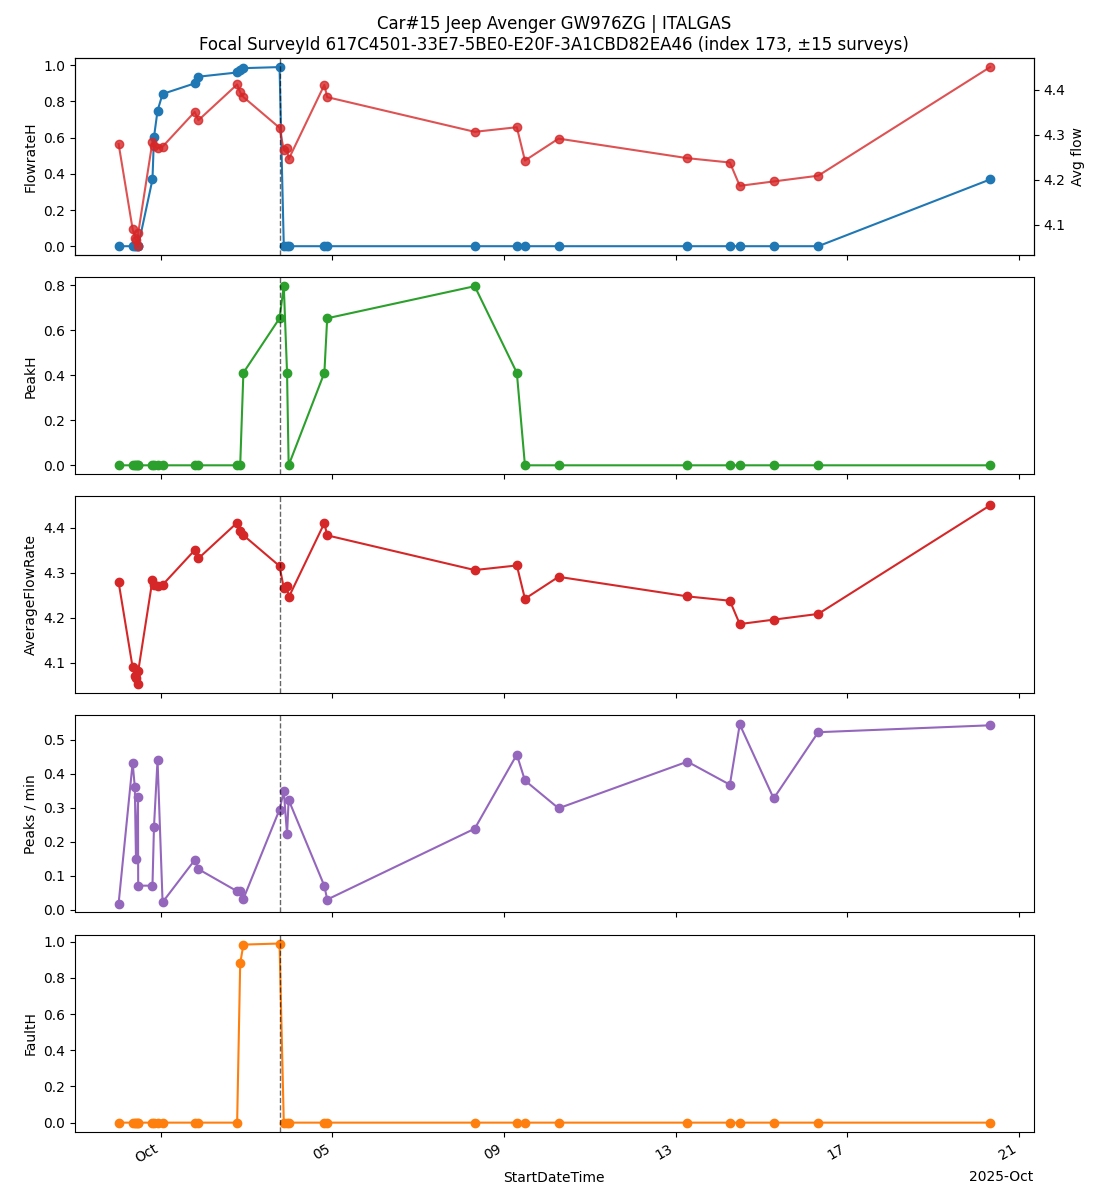

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def load_surveyor_series(surveyor_unit_id: str, db_path=None) -> pd.DataFrame:
    """All surveys for a unit, time-ordered, with detector + survey fields."""
    db_path = Path(db_path) if db_path is not None else Path.cwd() / "database" / "SystemHealthAlarm_Alarms.db"
    sql = """
    SELECT
        s.SurveyId,
        s.SurveyorUnitId,
        s.SurveyorUnit,
        s.CustomerName,
        s.StartDateTime,
        s.EndDateTime,
        s.AverageFlowRate,
        s.PeakCount,
        s.PeakMinutes,
        s.RawDurationMinutes,
        f.FaultH,
        fr.FlowrateH,
        pm.PeakH
    FROM SurveyData s
    LEFT JOIN FaultDetector f ON f.SurveyId = s.SurveyId
    LEFT JOIN FlowRateDetector fr ON fr.SurveyId = s.SurveyId
    LEFT JOIN PeakMinDetector pm ON pm.SurveyId = s.SurveyId
    WHERE s.SurveyorUnitId = ?
    ORDER BY s.StartDateTime, s.SurveyId
    """
    out = pd.read_sql_query(sql, f"sqlite:///{db_path}", params=(surveyor_unit_id,))
    out["StartDateTime"] = pd.to_datetime(out["StartDateTime"], errors="coerce")
    raw = pd.to_numeric(out["RawDurationMinutes"], errors="coerce").replace(0, pd.NA)
    peaks = pd.to_numeric(out["PeakCount"], errors="coerce")
    out["PeaksPerMinute"] = peaks / raw
    for col in ("FaultH", "FlowrateH", "PeakH", "AverageFlowRate"):
        out[col] = pd.to_numeric(out[col], errors="coerce")
    return out.reset_index(drop=True)


def plot_survey_context(
    survey_id: str,
    m: int = 10,
    surveyor_unit_id=None,
    db_path=None,
    mark_center: bool = True,
):
    """
    Plot PeakH, FlowrateH, AverageFlowRate, PeaksPerMinute, and FaultH for ±m surveys around survey_id.

    survey_id: SurveyId of the focal survey (e.g. from high_fault table).
    m: number of surveys before/after the focal survey (inclusive window).
    surveyor_unit_id: optional; looked up from DB if omitted.
    """
    db_path = Path(db_path) if db_path is not None else Path.cwd() / "database" / "SystemHealthAlarm_Alarms.db"

    if surveyor_unit_id is None:
        row = pd.read_sql_query(
            "SELECT SurveyorUnitId FROM SurveyData WHERE SurveyId = ?",
            f"sqlite:///{db_path}",
            params=(survey_id,),
        )
        if row.empty:
            raise ValueError(f"SurveyId not found: {survey_id}")
        surveyor_unit_id = row.iloc[0]["SurveyorUnitId"]

    unit = load_surveyor_series(surveyor_unit_id, db_path=db_path)
    hits = unit.index[unit["SurveyId"] == survey_id]
    if hits.empty:
        raise ValueError(f"SurveyId {survey_id} not in unit {surveyor_unit_id}")
    center = int(hits[0])
    lo = max(0, center - m)
    hi = min(len(unit) - 1, center + m)
    win = unit.iloc[lo : hi + 1].copy()
    t = win["StartDateTime"]
    focal_offset = center - lo
    meta = win.iloc[focal_offset]

    fig, axes = plt.subplots(5, 1, sharex=True, figsize=(11, 12))

    axes[0].plot(t, win["FlowrateH"], "o-", color="tab:blue", label="FlowrateH")
    ax0 = axes[0].twinx()
    ax0.plot(t, win["AverageFlowRate"], "o-", color="tab:red", alpha=0.8, label="AverageFlowRate")
    axes[0].set_ylabel("FlowrateH")
    ax0.set_ylabel("Avg flow")
    axes[0].set_title(
        f"{meta['SurveyorUnit']} | {meta['CustomerName']}\n"
        f"Focal SurveyId {survey_id} (index {center}, ±{m} surveys)"
    )

    axes[1].plot(t, win["PeakH"], "o-", color="tab:green")
    axes[1].set_ylabel("PeakH")

    axes[2].plot(t, win["AverageFlowRate"], "o-", color="tab:red")
    axes[2].set_ylabel("AverageFlowRate")

    axes[3].plot(t, win["PeaksPerMinute"], "o-", color="tab:purple")
    axes[3].set_ylabel("Peaks / min")

    axes[4].plot(t, win["FaultH"], "o-", color="tab:orange")
    axes[4].set_ylabel("FaultH")
    axes[4].set_xlabel("StartDateTime")

    if mark_center:
        focal_t = win.iloc[focal_offset]["StartDateTime"]
        for ax in axes:
            ax.axvline(focal_t, color="black", linestyle="--", linewidth=1, alpha=0.6)

    axes[4].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[4].xaxis.get_major_locator()))
    fig.autofmt_xdate()
    fig.tight_layout()
    return fig, win


# Example: plot context around the highest FaultH survey
if len(high_fault):
    example_id = high_fault.iloc[0]["SurveyId"]
    plot_survey_context(example_id, m=15)
    plt.show()
else:
    print("No surveys with FaultH > 0.90")


In [6]:
peak_min = peak_detector.sandbox_data['PeakH']
flowrate_h = flowrate_detector.sandbox_data['FlowrateH']
joint = peak_min * flowrate_h
peak_minutes = peak_detector.sandbox_data['PeakMinutes']
fig,ax = plt.subplots(3,1, sharex=True, figsize=(10,10))
ax00 = ax[0].twinx()
ax00.plot(flowrate_detector.sandbox_data['AverageFlowRate'], marker='o', markersize=10, color='red')
ax00.set_ylabel("AverageFlowRate")
ax[0].plot(flowrate_h, marker='o', markersize=10, color='blue')
ax[0].set_ylabel("FlowrateH")

ax[1].plot(peak_min, marker='o', markersize=10)
ax[1].set_ylabel("PeakH")
ax[2].plot(peak_minutes, marker='o', markersize=10)
ax20 = ax[2].twinx()
ax20.plot(peak_detector.sandbox_data['PeakI'], marker='o', markersize=10, color='green')
ax[2].set_ylabel("PeakMinutes")

NameError: name 'peak_detector' is not defined